In [7]:
import numpy as np
import math

'''
assumptions:
friction direction is always negative x
the ball rolls smooth
'''

#function to calculate the mass of the hole that is cut out
def calculate_mass_hole(mass_old:float, radius_cilinder:float, radius_hole:float):

    '''
    mass_old: the mass of the cilinder without a hole [kg] \\
    radius_cilinder: the radius of the complete cilinder [m] \\
    radius_hole: the radius of the hole we made in the cilinder [m]
    '''

    #calculating the mass of the taken out hole
    mass_hole = (radius_hole/radius_cilinder) ** 2 * mass_old
    return mass_hole

#funtion to calculate the moment of inertia of the cilinder with a hole
def calucate_moment_of_inertia(mass_old:float, radius_cilinder:float, radius_hole:float, offset_1:float, offset_2:float):

    '''
    mass_old: the mass of the cilinder without a hole [kg] \\
    radius_cilinder: the radius of the complete cilinder [m] \\
    radius_hole: the radius of the hole we made in the cilinder [m] \\
    offset_1: the distance between the center of mass and the rotation axis [m] \\
    offset_2: the distance between the center of the cut out hole and the rotation axis [m]
    '''

    #calculating the mass of the new cilinder with hole and mass of the hole
    mass_hole = calculate_mass_hole(mass_old, radius_cilinder, radius_hole)
    mass_new = mass_old - mass_hole

    #calculating the moment of inertia of the old cilinder and the hole of the cilinder
    moment_of_inertia_old_cilinder = 0.5 * mass_old * (radius_cilinder) ** 2
    moment_of_inertia_hole = 0.5 * mass_hole * (radius_hole) ** 2 + mass_hole * (offset_2) ** 2

    #calculating the moment of inertia of the new cilinder looking at it from the center of mass
    moment_of_inertia_cm = moment_of_inertia_old_cilinder - moment_of_inertia_hole

    #calculating the moment of inertia of the new cilinder looking at it form the ratation axis
    moment_of_inertia = moment_of_inertia_cm + mass_new * (offset_1) ** 2
    return moment_of_inertia

#calculating the acceleration and angular acceleration
def calculating_acceleration_and_alpha(moment_of_inertia:float, mass:float, radius:float, angle_center_of_mass:float, angle_slope:float, omega:float):

    '''
    moment_of_inertia: the moment of inertia of the cilinder with a hole [kg m^2] \\
    mass: the mass of the cilinder with hole [kg] \\
    radius: the radius of the cilinder [m] \\
    angle_center_of_mass: the angle of the center of mass of the cilinder with hole if you take the slope as the x-as [rad] \\
    angle_slope: the angle of the slope [rad]\\
    omega: the angular velocity of the cilinder
    '''
    
    #calculating the acceleration    
    acceleration = ((radius) ** 2 * mass * GRAVITATIONAL_VELOCITY * (np.sin(angle_slope) + np.cos(angle_slope - angle_center_of_mass))) / (((radius) ** 2) * mass + moment_of_inertia)
    
    # calculating the angular acceleration It's an asumption that it rols smoothly, that obivously doesn't happend if angle slope is bigger than 90 deg
    if angle_slope < np.deg2rad(90) % (2 * np.pi):
        alpha = -acceleration / radius

    else:
        alpha = 0

    return acceleration, alpha 

#calculating the distance between the center of mass and the rotation axis
def calculating_offset_1(distance_cilinder_cm_hole_cm:float, mass_old:float, radius_cilinder:float, radius_hole:float):
    
    '''
    distance_cilinder_cm_hole_cm: the distance between the old center of mass, before the hole was taken out, and the center of the taken out hole [m] \\
    mass_old: the mass of the cilinder without a hole [kg] \\
    radius_cilinder: the radius of the complete cilinder [m] \\
    radius_hole: the radius of the hole we made in the cilinder [m]    
    '''

    #calling the calculate_mass_function
    mass_hole = calculate_mass_hole(mass_old, radius_cilinder, radius_hole)

    #calculating the distance between the center of mass and the rotation axis
    offset_1 = abs((-1 * mass_hole*distance_cilinder_cm_hole_cm) / (-1 * mass_hole + mass_old))
    return offset_1

#function for calculating the energy
def calculating_energy(moment_of_inertia:float, velocity:float, mass_old:float, angular_velocity:float, radius_cilinder:float, radius_hole:float, angle_slope:float, length:float, position:float):
    
    '''
    moment_of_inertia: the moment of inertia of the cilinder with hole [kg m^2] \\
    velocity: the velocity of the cilinder with hole [m/s] \\
    angular_velocity: the angular velocity of the cilinder with hole [rad/s] \\
    mass_old: the mass of the cilinder without a hole [kg] \\
    radius_cilinder: the radius of the complete cilinder [m] \\
    radius_hole: the radius of the hole we made in the cilinder [m] \\
    angle_slope: the angle of the slope [rad] \\
    length: the distance the objects roles [m] \\
    position: the distance the object has already travelled [m]
    '''

    #calculating the height of the ball
    #wrong right now, because it calculates the height for the bottom of the ball instead of the center of mass 

    h = (length - position) * np.sin(angle_slope)


    #calculating the mass of the new cilinder with hole and mass of the hole
    mass_hole = calculate_mass_hole(mass_old, radius_cilinder, radius_hole)
    mass_new = mass_old - mass_hole

    #calculating the kinetic and potential energy
    kinetic_energy = 0.5 * mass_new * velocity ** 2 + 0.5 * moment_of_inertia * angular_velocity ** 2
    potential_engery = mass_new * GRAVITATIONAL_VELOCITY * h

    #calculating the total energy
    total_energy = kinetic_energy + potential_engery

    return total_energy

#constants
GRAVITATIONAL_VELOCITY = 9.81       #[m/s^2]
L = 10.0                            #[m]
MASS = 4.0                          #[kg]
RADIUS_CILINDER = 0.25              #[m]
RADIUS_HOLE = 0.025                 #[m]
OFFSET_2 = 0.125                    #[m]
OFFSET_1 = calculating_offset_1(OFFSET_2, MASS, RADIUS_CILINDER, RADIUS_HOLE) #[m]

#np array can have as many angles as you want
#it has to be in radians to work
ANGLE_SLOPE = np.array([np.deg2rad(20), np.deg2rad(30), np.deg2rad(40), np.deg2rad(50), np.deg2rad(60)])
I = calucate_moment_of_inertia(MASS, RADIUS_CILINDER, RADIUS_HOLE, OFFSET_1, OFFSET_2)    #[kg m^2]

#variables
t0 = 0                  #initial time [s]
v0 = 0                  #initial velocity [m/s]
x0 = 0                  #initial position [m]
phi0 = 0              #initial angle [rad]
omega0 = 0              #initial angular velocity = [rad/s]
dt = 1e-3               #time increments [s]
end_time = 5            #time the ball rolls [s]

#creating dictionaries
time_dic = {}
position_dic = {}
velocity_dic = {}
acceleration_dic = {}
angle_dic = {}
angular_velocity_dic = {}
angular_acceleration_dic = {}
total_energy_dic = {}

#giving initial values to there variables
x, phi, v, omega, t = x0, phi0, v0, omega0, t0

#if the offset is 0 the center of mass can't have a angle, so it's 0. this way the gravitational force doesn't exert torque
if OFFSET_1 > 0:
    a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, phi, ANGLE_SLOPE[0], omega)

else:
    a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, 0, ANGLE_SLOPE[0], omega)

#calculating begin energy
energy = calculating_energy(I, v, MASS, omega, RADIUS_CILINDER, RADIUS_HOLE, ANGLE_SLOPE[0], L, x)

#creating lists to add values of the variables to later
position = [x0]
velocity = [v0]
angle = [phi0]
angular_velocity = [omega0]
time = [t0]
acceleration = [a]
angular_acceleration = [alpha]
total_energy = [energy]
end_times = []

#for loop so that every slope angle has an calculation. f is to keep track of the how many times de loop has gone.
for theta, f in zip(ANGLE_SLOPE, range(len(ANGLE_SLOPE))):

    #reastablising the variables as there begin values for ANGLE_SLOPE 2, 3 ect. 
    x, phi, v, omega, t = x0, phi0, v0, omega0, t0

    # while loop in which the simulation takes place
    while True:
    
        #updating the variables every loop

        #if the offset is 0 the center of mass can't have a angle, so it's 0. this way the gravitational force doesn't exert torque
        if OFFSET_1 > 0:
            a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, phi, theta, omega)

        else:
            a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, 0, theta, omega)

        
        v = v + a * dt
        omega = omega + alpha * dt
        x = x + v * dt

        #you divide by 2 pi and take the remainder, because its easier to understand in the plot
        phi = (phi + omega * dt) % (-2 * np.pi)
        t = t + dt

        engery = calculating_energy(I, v, MASS, omega, RADIUS_CILINDER, RADIUS_HOLE, theta, L, x)

        #adding the variables to their lists
        position.append(x)
        velocity.append(v)
        angle.append(phi)
        angular_velocity.append(omega)
        time.append(t)
        acceleration.append(a)
        angular_acceleration.append(alpha)
        total_energy.append(engery)
        
        #condition to end the while loop. It's when the ball has gone further than the length of the planck
        if x >= L or t >= end_time:

            #adding every list to a dictionary under a diffrent name
            time_dic['time_{0}'.format(f)] = time
            velocity_dic['velocity_{0}'.format(f)] = velocity
            position_dic['position_{0}'.format(f)] = position
            acceleration_dic['acceleration_{0}'.format(f)] = acceleration
            angle_dic['angle_{0}'.format(f)] = angle
            angular_velocity_dic['angular_velocity_{0}'.format(f)] = angular_velocity
            angular_acceleration_dic['angular_acceleration_{0}'.format(f)] = angular_acceleration
            total_energy_dic['total_energy_{0}'.format(f)] = total_energy
            end_times.append(time[-1])

            #preperation for next simulation
            #to delete the old list so that is doesn't contain the values of the first simulation anymore
            #f + 1, because we still are in the old simulation loop, but you already want de values for the new simulation
            if f != len(ANGLE_SLOPE) - 1:

                a, alpha = calculating_acceleration_and_alpha(I, MASS, RADIUS_CILINDER, phi0, ANGLE_SLOPE[(f + 1)], omega)
                energy = calculating_energy(I, v0, MASS, omega0, RADIUS_CILINDER, RADIUS_HOLE, ANGLE_SLOPE[(f + 1)], L, x0)


                position = [x0]
                velocity = [v0]
                angle = [phi0]
                angular_velocity = [omega0]
                time = [t0]
                acceleration = [a]
                angular_acceleration = [alpha]
                total_energy = [energy]
  
            break

<>:93: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:93: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\qwpie\AppData\Local\Temp\ipykernel_31012\734393740.py:93: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  ax[0, 1].yaxis.set_major_formatter(tck.FormatStrFormatter('%g $\pi$'))


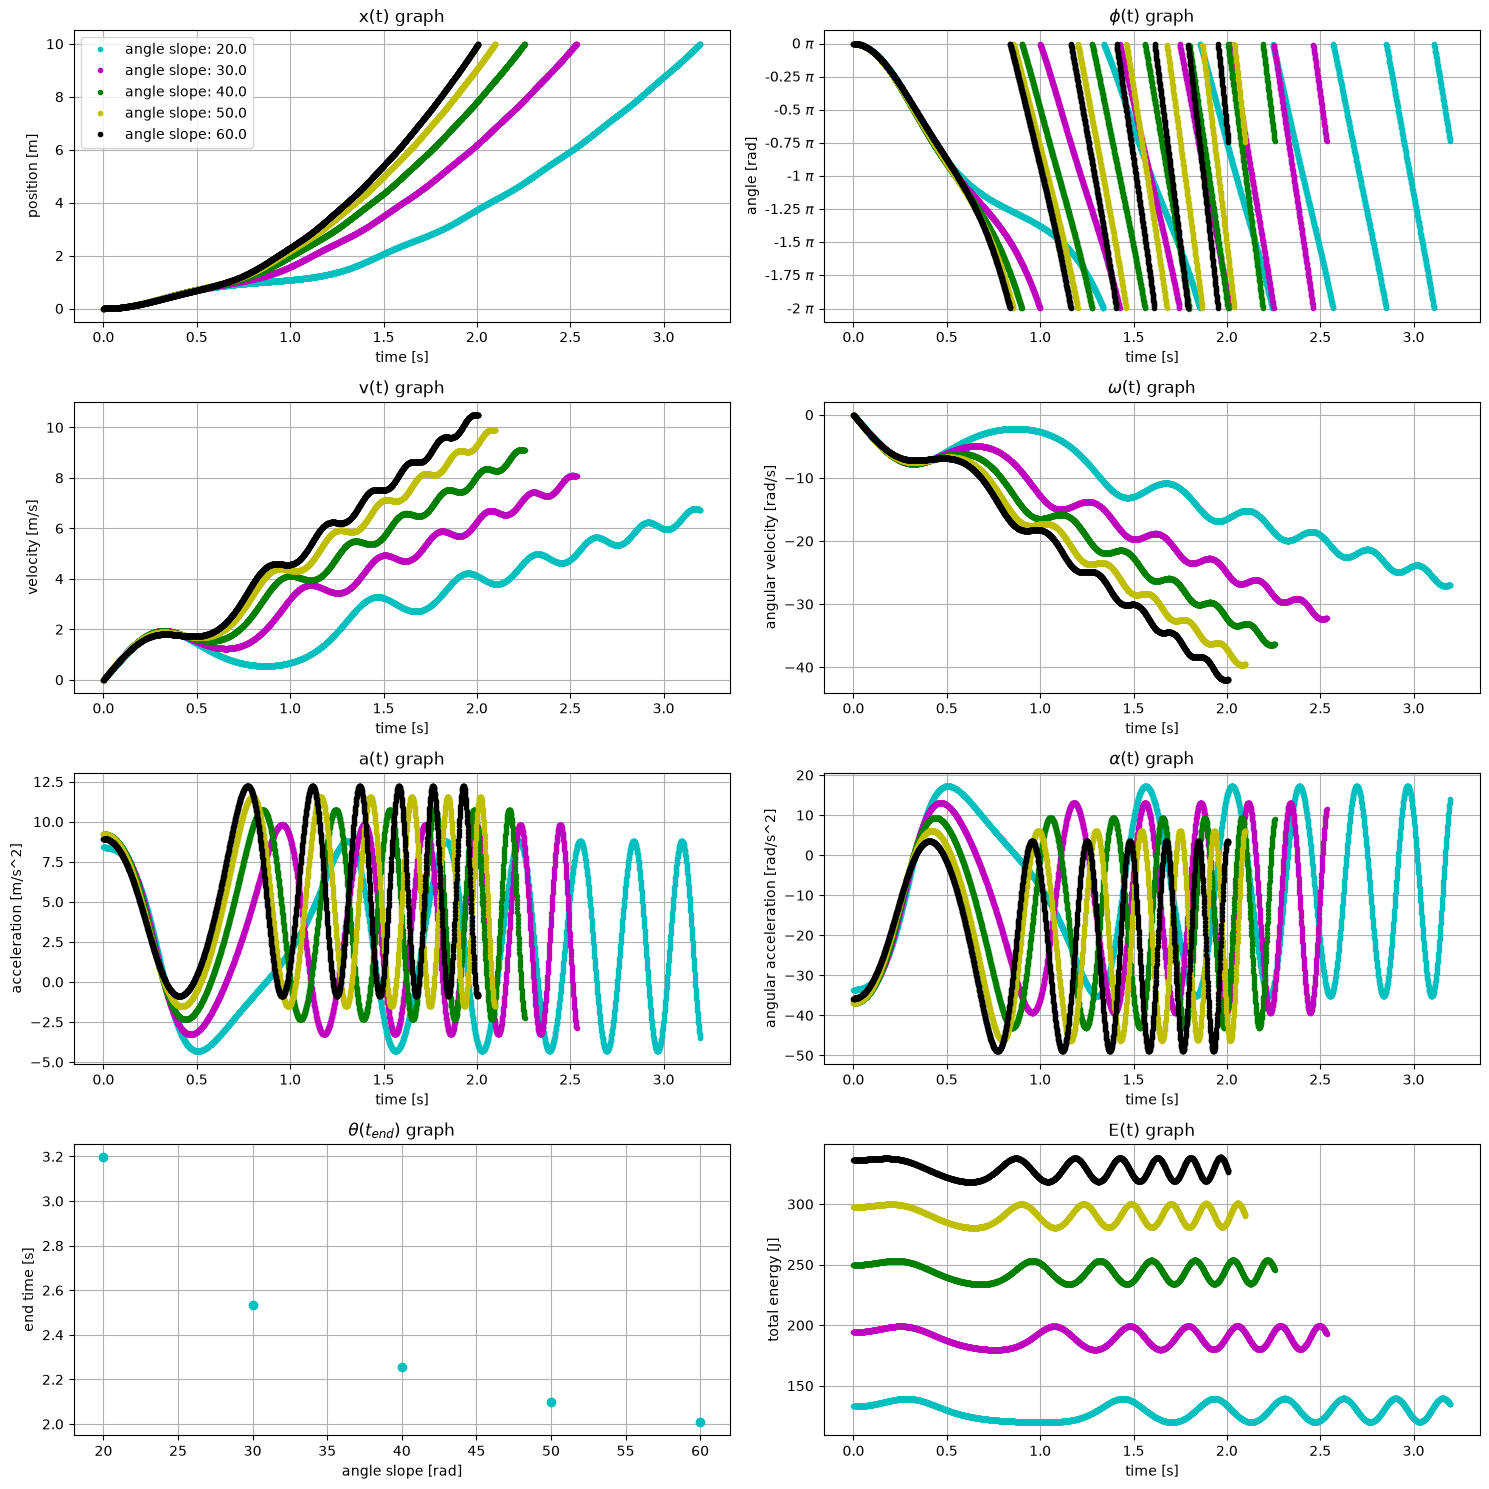

In [8]:
import matplotlib.pyplot as plt
import matplotlib.ticker as tck

#creating a enviorment for the plots
fig, ax = plt.subplots(4, 2, figsize = (15, 15))


#for loop to plot all the simulations
for e_value, p_value, v_value, ac_value, an_value, an_v_value, an_ac_value, t_value, i in zip(total_energy_dic.values(), position_dic.values(), velocity_dic.values(), acceleration_dic.values(), angle_dic.values(), angular_velocity_dic.values(), angular_acceleration_dic.values(), time_dic.values(), range(len(ANGLE_SLOPE))):

    an_value_new = []
    
    #to get the simulations for the diffrent angles a diffrent color.
    if i%6 == 0:
        color_dot = 'c.' 
    elif i%6 == 1:
        color_dot = 'm.'
    elif i%6 == 2:
        color_dot = 'g.'
    elif i%6 == 3:
         color_dot = 'y.'
    elif i%6 == 4:
        color_dot = 'k.'
    else:
        color_dot = 'b.'

    #calculating the angels in pi so it is easier to understand
    for an in an_value:
        an_value_new.append(an / np.pi)

    #plotting all the simulations
    ax[0, 0].plot(t_value, p_value, color_dot, label= f'angle slope: {np.rad2deg(ANGLE_SLOPE[i]):.1f}')
    ax[1, 0].plot(t_value, v_value, color_dot)
    ax[2, 0].plot(t_value, ac_value, color_dot)
    ax[0, 1].plot(t_value, an_value_new, color_dot)
    ax[1, 1].plot(t_value, an_v_value, color_dot)
    ax[2, 1].plot(t_value, an_ac_value, color_dot)
    ax[3, 1].plot(t_value, e_value, color_dot)

#plotting end time against angle slope
ax[3,0].plot(np.rad2deg(ANGLE_SLOPE), end_times, 'co')

#setting x/y labels to the plots
ax[0, 0].set(
    xlabel= 'time [s]',
    ylabel = 'position [m]',
    title= 'x(t) graph'
)

ax[1, 0].set(
    xlabel= 'time [s]',
    ylabel = 'velocity [m/s]',
    title = 'v(t) graph'
)

ax[2, 0].set(
    xlabel= 'time [s]',
    ylabel = 'acceleration [m/s^2]',
    title = 'a(t) graph'
)

ax[0, 1].set(
    xlabel= 'time [s]',
    ylabel = 'angle [rad]',
    title = r'$\phi$(t) graph'
)

ax[1, 1].set(
    xlabel= 'time [s]',
    ylabel = 'angular velocity [rad/s]',
    title = r'$\omega$(t) graph'
)

ax[2, 1].set(
    xlabel= 'time [s]',
    ylabel = 'angular acceleration [rad/s^2]',
    title = r'$\alpha$(t) graph'
)

ax[3, 0].set(
    xlabel= 'angle slope [rad]',
    ylabel= 'end time [s]',
    title = r'$\theta$($t_{end}$) graph'
)

ax[3, 1].set(
    xlabel= 'time [s]',
    ylabel= 'total energy [J]',
    title = 'E(t) graph'
)

#adds pi to after the numbers, so the angels are easier to understand
ax[0, 1].yaxis.set_major_formatter(tck.FormatStrFormatter('%g $\pi$'))

#adding grids to the plots
ax[0, 0].legend()
ax[0, 0].grid()
ax[1, 0].grid()
ax[0, 1].grid()
ax[1, 1].grid()
ax[2, 0].grid()
ax[2, 1].grid()
ax[3, 0].grid()
ax[3, 1].grid()

#fig.suptitle('Simulation of a cilinder with a off centered center of mass')

#showing the plots and reducing the spacing
plt.tight_layout()
plt.show()